# Language Model Probability Math: Theory Notebook

This notebook is the executable companion to `notes.md`. It turns the probability formulas behind LLMs into small, inspectable computations: chain-rule scoring, stable softmax, cross-entropy gradients, perplexity, calibration, and decoding.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl

try:
    import seaborn as sns
    sns.set_theme(style="whitegrid", palette="colorblind")
    HAS_SNS = True
except ImportError:
    plt.style.use("seaborn-v0_8-whitegrid")
    HAS_SNS = False

mpl.rcParams.update({
    "figure.figsize":    (10, 6),
    "figure.dpi":         120,
    "font.size":           13,
    "axes.titlesize":      15,
    "axes.labelsize":      13,
    "xtick.labelsize":     11,
    "ytick.labelsize":     11,
    "legend.fontsize":     11,
    "legend.framealpha":   0.85,
    "lines.linewidth":      2.0,
    "axes.spines.top":     False,
    "axes.spines.right":   False,
    "savefig.bbox":       "tight",
    "savefig.dpi":         150,
})
np.random.seed(42)
print("Plot setup complete.")

Plot setup complete.


## 1. A tiny autoregressive language model

A language model gives a next-token distribution for every prefix. In a real LLM, the prefix is encoded by a transformer. Here, a dictionary is enough to expose the probability bookkeeping.

In [2]:
vocab = ["<BOS>", "the", "cat", "sat", "slept", "<EOS>"]

toy_next = {
    ("<BOS>",): {"the": 0.90, "cat": 0.05, "slept": 0.05},
    ("<BOS>", "the"): {"cat": 0.75, "sat": 0.10, "slept": 0.10, "<EOS>": 0.05},
    ("<BOS>", "the", "cat"): {"sat": 0.55, "slept": 0.35, "<EOS>": 0.10},
    ("<BOS>", "the", "cat", "sat"): {"<EOS>": 0.80, "slept": 0.20},
}

def next_prob(prefix, token):
    dist = toy_next.get(tuple(prefix), {"<EOS>": 1.0})
    return dist.get(token, 1e-12)

sentence = ["<BOS>", "the", "cat", "sat", "<EOS>"]
logp = 0.0
for i in range(1, len(sentence)):
    prefix = sentence[:i]
    token = sentence[i]
    prob = next_prob(prefix, token)
    logp += np.log(prob)
    print(f"{prefix} -> {token:>5s}: p={prob:.3f}, cumulative logp={logp:.3f}")

print("sequence probability =", float(np.exp(logp)))

['<BOS>'] ->   the: p=0.900, cumulative logp=-0.105
['<BOS>', 'the'] ->   cat: p=0.750, cumulative logp=-0.393
['<BOS>', 'the', 'cat'] ->   sat: p=0.550, cumulative logp=-0.991
['<BOS>', 'the', 'cat', 'sat'] -> <EOS>: p=0.800, cumulative logp=-1.214
sequence probability = 0.29700000000000004


## 2. Chain rule versus independence

The chain rule is exact. The approximation is not the product rule itself; the approximation is how the model estimates each conditional.

In [3]:
joint_by_chain = 0.90 * 0.75 * 0.55 * 0.80
bad_independent = 0.40 * 0.30 * 0.10 * 0.20
print("chain-rule probability:", joint_by_chain)
print("independence-style product:", bad_independent)
print("ratio:", joint_by_chain / bad_independent)

chain-rule probability: 0.2970000000000001
independence-style product: 0.0024000000000000002
ratio: 123.75000000000003


## 3. N-gram smoothing as a probability ancestor

Before neural LMs, count models estimated $P(w_i \mid w_{i-n+1:i-1})$. Additive smoothing makes unseen events nonzero.

In [4]:
corpus = [
    ["<BOS>", "the", "cat", "sat", "<EOS>"],
    ["<BOS>", "the", "cat", "slept", "<EOS>"],
    ["<BOS>", "the", "cat", "sat", "<EOS>"],
    ["<BOS>", "the", "dog", "sat", "<EOS>"],
]
vocab2 = sorted({tok for sent in corpus for tok in sent})
alpha = 0.5

from collections import Counter, defaultdict
counts = defaultdict(Counter)
for sent in corpus:
    for a, b in zip(sent[:-1], sent[1:]):
        counts[a][b] += 1

def smoothed_bigram(prev, tok):
    return (counts[prev][tok] + alpha) / (sum(counts[prev].values()) + alpha * len(vocab2))

for tok in vocab2:
    print(f"P({tok:>5s} | the) = {smoothed_bigram('the', tok):.3f}")
print("normalization:", sum(smoothed_bigram("the", tok) for tok in vocab2))

P(<BOS> | the) = 0.067
P(<EOS> | the) = 0.067
P(  cat | the) = 0.467
P(  dog | the) = 0.200
P(  sat | the) = 0.067
P(slept | the) = 0.067
P(  the | the) = 0.067
normalization: 1.0


## 4. Stable softmax and log-softmax

Large logits can overflow if exponentiated directly. Subtracting the maximum logit preserves probabilities and stabilizes the computation.

In [5]:
def softmax(z, tau=1.0):
    z = np.asarray(z, dtype=float) / tau
    z = z - z.max()
    exp_z = np.exp(z)
    return exp_z / exp_z.sum()

def log_softmax(z):
    z = np.asarray(z, dtype=float)
    m = z.max()
    lse = m + np.log(np.exp(z - m).sum())
    return z - lse

logits = np.array([1002.0, 1001.0, 999.0, 995.0])
p = softmax(logits)
lp = log_softmax(logits)
print("probabilities:", np.round(p, 6))
print("sum:", p.sum())
print("log probs:", np.round(lp, 6))
print("exp(log probs):", np.round(np.exp(lp), 6))

probabilities: [7.04931e-01 2.59330e-01 3.50960e-02 6.43000e-04]
sum: 1.0000000000000002
log probs: [-0.349655 -1.349655 -3.349655 -7.349655]
exp(log probs): [7.04931e-01 2.59330e-01 3.50960e-02 6.43000e-04]


## 5. Temperature changes entropy

Temperature rescales logits before softmax. Low temperature sharpens; high temperature flattens.

tau=0.4: entropy=0.309, top prob=0.918
tau=0.7: entropy=0.718, top prob=0.761
tau=1.0: entropy=1.000, top prob=0.636
tau=1.5: entropy=1.264, top prob=0.505
tau=2.5: entropy=1.464, top prob=0.381


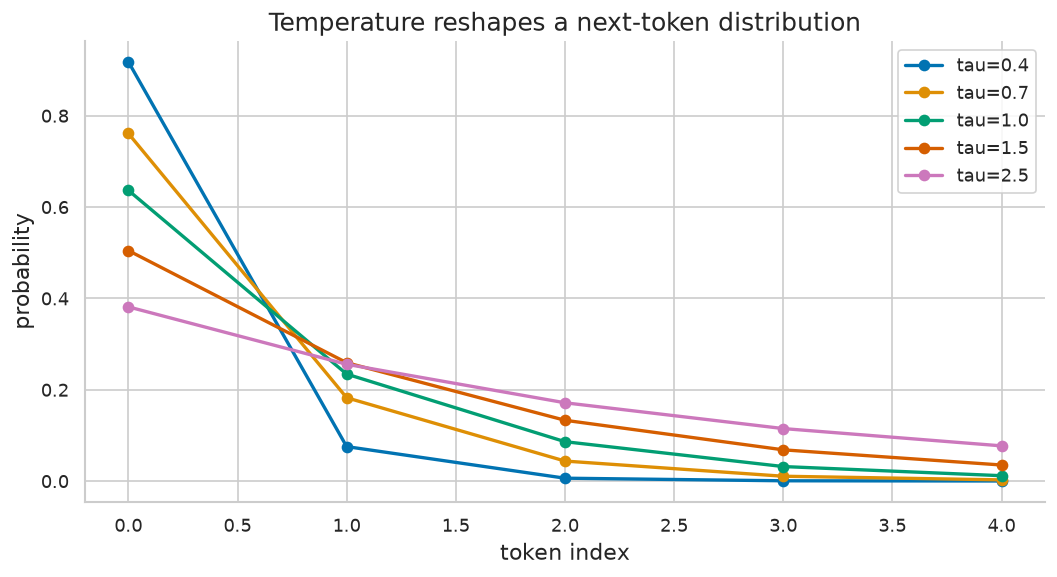

In [6]:
temps = [0.4, 0.7, 1.0, 1.5, 2.5]
base_logits = np.array([3.0, 2.0, 1.0, 0.0, -1.0])

fig, ax = plt.subplots(figsize=(9, 5))
for tau in temps:
    probs = softmax(base_logits, tau=tau)
    ax.plot(range(len(base_logits)), probs, marker="o", label=f"tau={tau}")
    entropy = -(probs * np.log(probs + 1e-12)).sum()
    print(f"tau={tau:>3}: entropy={entropy:.3f}, top prob={probs.max():.3f}")
ax.set_title("Temperature reshapes a next-token distribution")
ax.set_xlabel("token index")
ax.set_ylabel("probability")
ax.legend()
fig.tight_layout()
plt.show()

## 6. Cross-entropy gradient

For one observed target token, the loss is $-\log p_y$. The derivative with respect to logits is $p-y$.

In [7]:
z = np.array([1.2, -0.3, 0.7, 2.1])
target = 3
p = softmax(z)
y = np.eye(len(z))[target]
analytic_grad = p - y

def ce_loss(zvec):
    return -log_softmax(zvec)[target]

eps = 1e-5
numeric_grad = np.zeros_like(z)
for i in range(len(z)):
    step = np.zeros_like(z)
    step[i] = eps
    numeric_grad[i] = (ce_loss(z + step) - ce_loss(z - step)) / (2 * eps)

print("probabilities:", np.round(p, 5))
print("analytic grad:", np.round(analytic_grad, 5))
print("numeric grad: ", np.round(numeric_grad, 5))
print("max error:", np.max(np.abs(analytic_grad - numeric_grad)))

probabilities: [0.23314 0.05202 0.14141 0.57343]
analytic grad: [ 0.23314  0.05202  0.14141 -0.42657]
numeric grad:  [ 0.23314  0.05202  0.14141 -0.42657]
max error: 2.077188421267806e-11


## 7. Masked token loss

Padded tokens should not contribute to the mean loss. Many training bugs are just masking bugs.

In [8]:
token_losses = np.array([
    [1.1, 0.9, 0.7, 0.0],
    [1.5, 1.3, 0.0, 0.0],
])
mask = np.array([
    [1, 1, 1, 0],
    [1, 1, 0, 0],
])
masked_mean = (token_losses * mask).sum() / mask.sum()
bad_mean = token_losses.mean()
print("masked mean loss:", masked_mean)
print("unmasked mean loss:", bad_mean)
print("difference:", masked_mean - bad_mean)

masked mean loss: 1.1
unmasked mean loss: 0.6875
difference: 0.4125000000000001


## 8. Entropy, cross-entropy, KL, and perplexity

Cross-entropy can be decomposed into irreducible data entropy plus model mismatch.

In [9]:
q = np.array([0.70, 0.20, 0.10])
p_good = np.array([0.65, 0.25, 0.10])
p_bad = np.array([0.20, 0.30, 0.50])

def entropy(dist):
    return -(dist * np.log(dist + 1e-12)).sum()

def cross_entropy(q, p):
    return -(q * np.log(p + 1e-12)).sum()

def kl(q, p):
    return (q * (np.log(q + 1e-12) - np.log(p + 1e-12))).sum()

for name, model in [("good", p_good), ("bad", p_bad)]:
    ce = cross_entropy(q, model)
    print(name, "CE=", round(ce, 4), "H+KL=", round(entropy(q) + kl(q, model), 4), "PPL=", round(np.exp(ce), 4))

good CE= 0.8091 H+KL= 0.8091 PPL= 2.2458
bad CE= 1.4367 H+KL= 1.4367 PPL= 4.2069


## 9. Length normalization

Raw log probability usually favors shorter outputs. Average log probability asks how surprising each token is.

In [10]:
candidates = {
    "short": np.array([-0.20, -0.40]),
    "long_better_per_token": np.array([-0.32, -0.34, -0.35, -0.33, -0.34, -0.32]),
}
for name, logps in candidates.items():
    print(name)
    print("  total logp:", float(logps.sum()))
    print("  mean logp: ", float(logps.mean()))
    print("  perplexity:", float(np.exp(-logps.mean())))

short
  total logp: -0.6000000000000001
  mean logp:  -0.30000000000000004
  perplexity: 1.3498588075760032
long_better_per_token
  total logp: -2.0
  mean logp:  -0.3333333333333333
  perplexity: 1.3956124250860895


## 10. Expected calibration error

Calibration compares confidence to empirical correctness. A model can have high accuracy and still be overconfident.

In [11]:
conf = np.array([0.95, 0.90, 0.85, 0.80, 0.75, 0.70, 0.60, 0.55, 0.45, 0.30])
correct = np.array([1, 1, 0, 1, 0, 1, 0, 0, 0, 0])
bins = np.linspace(0.0, 1.0, 6)

ece = 0.0
for lo, hi in zip(bins[:-1], bins[1:]):
    in_bin = (conf > lo) & (conf <= hi)
    if not in_bin.any():
        continue
    acc = correct[in_bin].mean()
    avg_conf = conf[in_bin].mean()
    weight = in_bin.mean()
    ece += weight * abs(acc - avg_conf)
    print(f"({lo:.1f}, {hi:.1f}] n={in_bin.sum()} acc={acc:.3f} conf={avg_conf:.3f}")
print("ECE:", round(ece, 4))

(0.2, 0.4] n=1 acc=0.000 conf=0.300
(0.4, 0.6] n=3 acc=0.000 conf=0.533
(0.6, 0.8] n=3 acc=0.667 conf=0.750
(0.8, 1.0] n=3 acc=0.667 conf=0.900
ECE: 0.285


## 11. Top-k and top-p filtering

Filtering changes the distribution used for decoding. It does not retrain the model.

In [12]:
def top_k_filter(probs, k):
    probs = np.asarray(probs, dtype=float)
    keep = np.argsort(probs)[-k:]
    out = np.zeros_like(probs)
    out[keep] = probs[keep]
    return out / out.sum()

def top_p_filter(probs, p_cut):
    probs = np.asarray(probs, dtype=float)
    order = np.argsort(probs)[::-1]
    cumulative = np.cumsum(probs[order])
    keep_sorted = cumulative <= p_cut
    keep_sorted[0] = True
    if not keep_sorted.all():
        keep_sorted[np.argmax(cumulative > p_cut)] = True
    keep = order[keep_sorted]
    out = np.zeros_like(probs)
    out[keep] = probs[keep]
    return out / out.sum()

probs = softmax(np.array([4.0, 3.0, 2.2, 1.5, 0.5, -0.5]))
print("base: ", np.round(probs, 3))
print("top-k:", np.round(top_k_filter(probs, 3), 3))
print("top-p:", np.round(top_p_filter(probs, 0.82), 3))

base:  [0.604 0.222 0.1   0.05  0.018 0.007]
top-k: [0.652 0.24  0.108 0.    0.    0.   ]
top-p: [0.731 0.269 0.    0.    0.    0.   ]


## 12. Beam search as approximate sequence MAP

Beam search keeps several partial hypotheses, trading diversity for higher sequence score.

In [13]:
transitions = {
    (): {"A": 0.55, "B": 0.45},
    ("A",): {"x": 0.52, "y": 0.48},
    ("B",): {"x": 0.90, "y": 0.10},
    ("A", "x"): {"<EOS>": 1.0},
    ("A", "y"): {"<EOS>": 1.0},
    ("B", "x"): {"<EOS>": 1.0},
    ("B", "y"): {"<EOS>": 1.0},
}

beam = [((), 0.0)]
for step in range(3):
    expanded = []
    for prefix, score in beam:
        if prefix and prefix[-1] == "<EOS>":
            expanded.append((prefix, score))
            continue
        for tok, prob in transitions[prefix].items():
            expanded.append((prefix + (tok,), score + np.log(prob)))
    beam = sorted(expanded, key=lambda x: x[1], reverse=True)[:2]
    print("step", step + 1, beam)

step 1 [(('A',), np.float64(-0.5978370007556204)), (('B',), np.float64(-0.7985076962177716))]
step 2 [(('B', 'x'), np.float64(-0.9038682118755978)), (('A', 'x'), np.float64(-1.2517634681622845))]
step 3 [(('B', 'x', '<EOS>'), np.float64(-0.9038682118755978)), (('A', 'x', '<EOS>'), np.float64(-1.2517634681622845))]


## 13. Tied embeddings and the LM head

Many LMs use the same matrix for input embeddings and output logits. The probability math is unchanged; the parameterization changes.

In [14]:
vocab_size, d_model = 7, 4
E = np.random.normal(size=(vocab_size, d_model))
h = np.random.normal(size=(d_model,))
logits_tied = E @ h
probs_tied = softmax(logits_tied)
print("embedding table shape:", E.shape)
print("hidden state shape:", h.shape)
print("logits shape:", logits_tied.shape)
print("probability sum:", probs_tied.sum())

embedding table shape: (7, 4)
hidden state shape: (4,)
logits shape: (7,)
probability sum: 1.0


## 14. Conditional scoring

For prompt-answer scoring, average over answer tokens, not prompt tokens, unless the task explicitly asks for full string likelihood.

In [15]:
prompt_logps = np.array([-0.1, -0.2, -0.1, -0.3])
answer_a = np.array([-0.4, -0.5, -0.4])
answer_b = np.array([-0.2])

print("full score A:", np.r_[prompt_logps, answer_a].mean())
print("full score B:", np.r_[prompt_logps, answer_b].mean())
print("answer-only score A:", answer_a.mean())
print("answer-only score B:", answer_b.mean())
print("Choose the scoring convention before comparing.")

full score A: -0.2857142857142857
full score B: -0.18
answer-only score A: -0.43333333333333335
answer-only score B: -0.2
Choose the scoring convention before comparing.


## 15. Logit bias as a constraint

Adding a large negative bias can effectively ban a token. Adding a positive bias can encourage a token family.

In [16]:
labels = ["safe", "maybe", "banned", "other"]
logits = np.array([2.0, 1.5, 1.2, 0.5])
bias = np.array([0.0, 0.0, -20.0, 0.0])

before = softmax(logits)
after = softmax(logits + bias)
for lab, b, a in zip(labels, before, after):
    print(f"{lab:>6s}: before={b:.4f}, after={a:.8f}")

  safe: before=0.4388, after=0.54654939
 maybe: before=0.2661, after=0.33149896
banned: before=0.1972, after=0.00000000
 other: before=0.0979, after=0.12195165


## 16. Tokenizer-dependent perplexity

Per-token perplexity is not directly comparable across tokenizers with different token counts. Bits per byte or bits per character can be fairer when the text is identical.

In [17]:
nll_same_text = 12.0
tokens_a = 6
tokens_b = 10
bytes_count = 32

ppl_a = np.exp(nll_same_text / tokens_a)
ppl_b = np.exp(nll_same_text / tokens_b)
bpb = nll_same_text / np.log(2) / bytes_count
print("PPL tokenizer A:", round(ppl_a, 3))
print("PPL tokenizer B:", round(ppl_b, 3))
print("bits per byte:", round(bpb, 3))

PPL tokenizer A: 7.389
PPL tokenizer B: 3.32
bits per byte: 0.541


## 17. Final probability implementation checklist

In [18]:
checks = [
    "softmax sums to one on the vocabulary axis",
    "log-softmax uses log-sum-exp stabilization",
    "targets are shifted by one position",
    "causal mask prevents future leakage",
    "padding and prompt masks are applied before averaging",
    "sequence comparisons state the length convention",
    "perplexity comparisons state tokenizer and dataset",
]
for i, check in enumerate(checks, 1):
    print(f"{i}. {check}")

1. softmax sums to one on the vocabulary axis
2. log-softmax uses log-sum-exp stabilization
3. targets are shifted by one position
4. causal mask prevents future leakage
5. padding and prompt masks are applied before averaging
6. sequence comparisons state the length convention
7. perplexity comparisons state tokenizer and dataset


## 18. Conditional entropy and mutual information (new)

Section 11 of the notes: $I(X;Y)=H(Y)-H(Y\mid X)$. We compute it for a 90%-accurate symmetric context and check the conditioning inequality numerically.

In [19]:
acc=0.90
h_cond=-(acc*np.log(acc)+(1-acc)*np.log(1-acc))
h_marg=np.log(2)
mi=h_marg-h_cond
print(f"H(Y)={h_marg:.4f} nats, H(Y|X)={h_cond:.4f} nats, I(X;Y)={mi:.4f} nats = {mi/np.log(2):.3f} bits")
ok=h_cond<=h_marg+1e-12 and abs(mi-0.368)>0
print(f"{'PASS' if ok else 'FAIL'} - conditioning does not increase entropy")

H(Y)=0.6931 nats, H(Y|X)=0.3251 nats, I(X;Y)=0.3681 nats = 0.531 bits
PASS - conditioning does not increase entropy


## 19. Temperature entropy is monotone (new)

Section 12.2: entropy of $p(\tau)\propto p^{1/\tau}$ should not decrease as temperature rises.

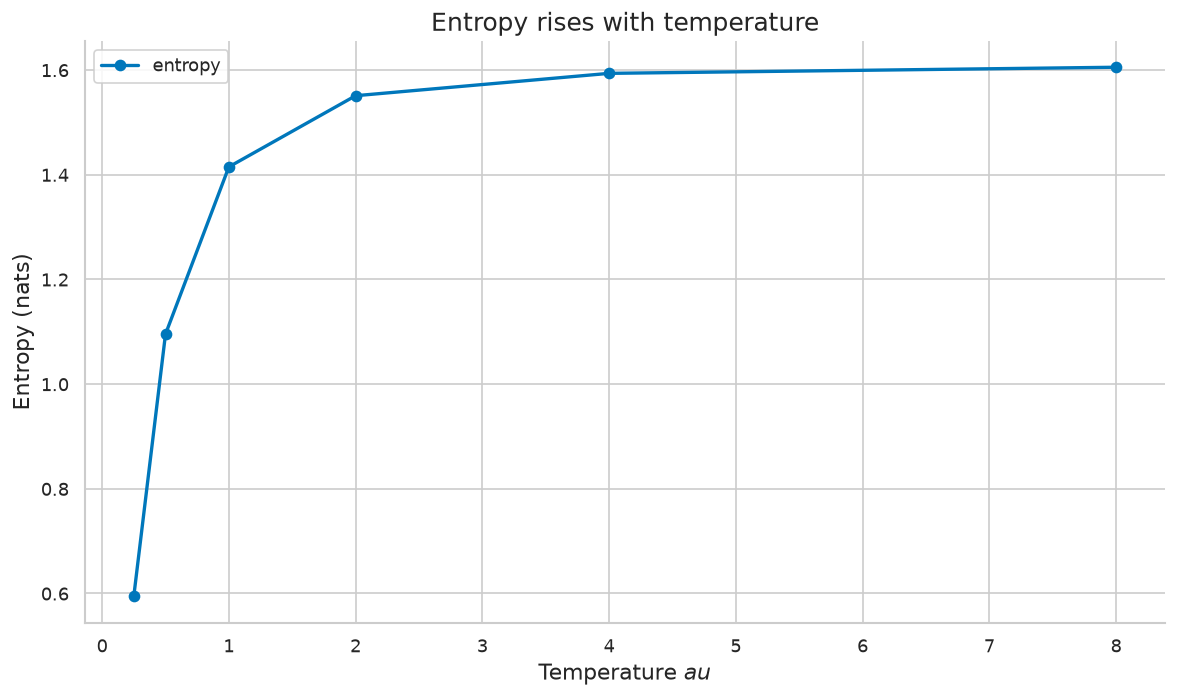

entropies: [0.5951 1.0955 1.415  1.551  1.5937 1.6054]
PASS - entropy is non-decreasing in temperature


In [20]:
base=np.array([0.40,0.25,0.20,0.10,0.05])
taus=np.array([0.25,0.5,1.0,2.0,4.0,8.0])
ents=[]
for tau in taus:
    q=base**(1.0/tau); q=q/q.sum(); ents.append(-(q*np.log(q)).sum())
ents=np.array(ents)
fig, ax = plt.subplots()
ax.plot(taus, ents, color="#0077BB", marker="o", label="entropy")
ax.set_title("Entropy rises with temperature")
ax.set_xlabel("Temperature $\tau$"); ax.set_ylabel("Entropy (nats)"); ax.legend(loc="best"); fig.tight_layout(); plt.show()
print("entropies:", np.round(ents,4))
ok=np.all(np.diff(ents)>=-1e-9)
print(f"{'PASS' if ok else 'FAIL'} - entropy is non-decreasing in temperature")

## 20. Top-p discarded mass equals TV distance (new)

Section 12.3 / Problem 7: compute a nucleus filter and verify the discarded mass.

In [21]:
p=np.array([0.45,0.25,0.15,0.10,0.05])
order=np.argsort(-p); cum=np.cumsum(p[order]); k=int(np.searchsorted(cum,0.90)+1)
keep=np.zeros_like(p); keep[order[:k]]=p[order[:k]]; filt=keep/keep.sum(); discarded=1-keep.sum()
print("kept tokens:", order[:k], "filtered:", np.round(filt,4), "discarded:", round(float(discarded),4))
ok=abs(discarded-0.05)<1e-12 and abs(filt.sum()-1)<1e-12
print(f"{'PASS' if ok else 'FAIL'} - filtered distribution normalized, discarded mass matches")

kept tokens: [0 1 2 3] filtered: [0.4737 0.2632 0.1579 0.1053 0.    ] discarded: 0.05
PASS - filtered distribution normalized, discarded mass matches


## 21. Label smoothing caps the optimal confidence (new)

Section 15.1 with $\varepsilon=0.1$, $|V|=4$: the loss-minimizing prediction equals the smoothed target, not a one-hot.

In [22]:
eps,V=0.1,4; target=np.array([1.0,0,0,0]); smoothed=(1-eps)*target+eps/V
def ce(t,p): return float(-(t*np.log(p)).sum())
cands=[target, smoothed, np.full(V,0.25)]
vals=[ce(smoothed,c) for c in cands]
print("smoothed target:", smoothed, "CE values:", np.round(vals,4))
ok=vals[1]<=vals[0] and vals[1]<=vals[2]
print(f"{'PASS' if ok else 'FAIL'} - smoothed target minimizes smoothed cross-entropy")

smoothed target: [0.925 0.025 0.025 0.025] CE values: [   inf 0.3488 1.3863]
PASS - smoothed target minimizes smoothed cross-entropy


/tmp/ipykernel_7827/733727506.py:2: RuntimeWarning: divide by zero encountered in log
  def ce(t,p): return float(-(t*np.log(p)).sum())


## 22. Bits per byte is tokenizer-free (new)

Section 16.1: same text, two tokenizers, different per-token perplexities but the same bits per byte.

In [23]:
total_nll_nats=120.0; bytes_count=320
for name,toks in [("tokenizer A",60),("tokenizer B",100)]:
    mean=total_nll_nats/toks; print(f"{name}: mean NLL={mean:.3f} nats, ppl={np.exp(mean):.3f}, bits/byte={total_nll_nats/np.log(2)/bytes_count:.4f}")
bpb=total_nll_nats/np.log(2)/bytes_count
ok=abs(bpb-0.5412)<1e-3
print(f"{'PASS' if ok else 'FAIL'} - bits per byte independent of token count: {bpb:.4f}")

tokenizer A: mean NLL=2.000 nats, ppl=7.389, bits/byte=0.5410
tokenizer B: mean NLL=1.200 nats, ppl=3.320, bits/byte=0.5410
PASS - bits per byte independent of token count: 0.5410


## 23. Expected calibration error by hand (new)

Problem 6 from the notes, encoded as an executable check with a calibration plot using the Wong palette.

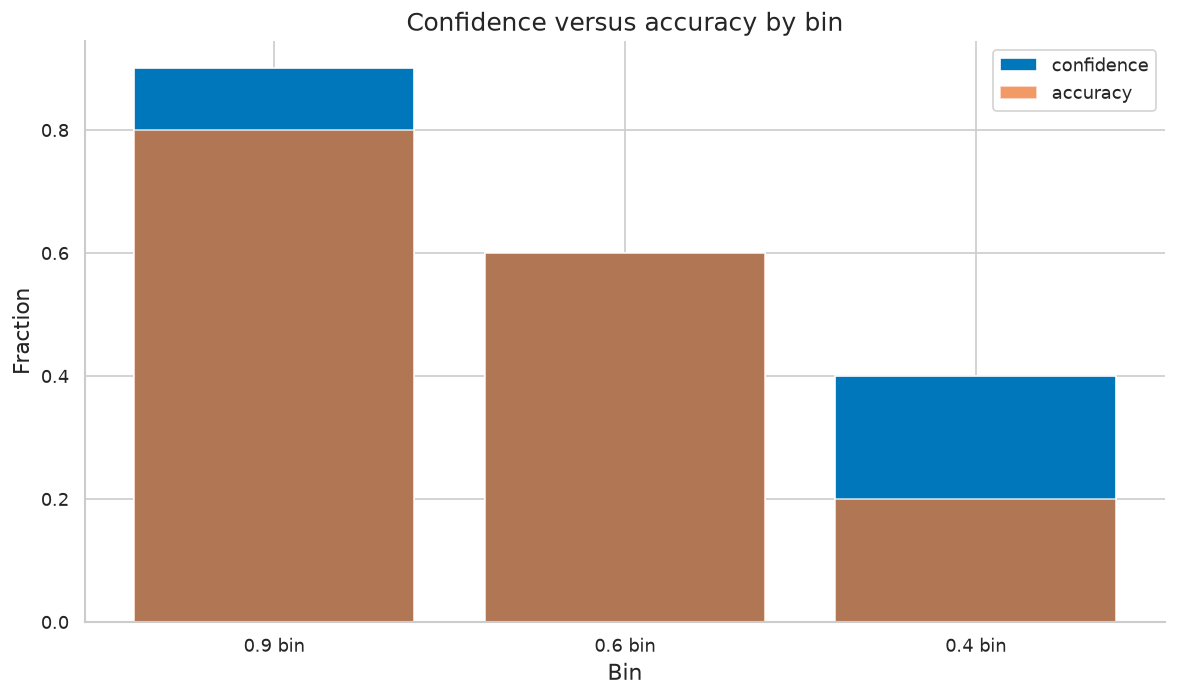

ECE=0.0900
PASS - ECE matches hand calculation 0.09


In [24]:
conf=np.array([0.9,0.6,0.4]); acc=np.array([0.8,0.6,0.2]); w=np.array([0.5,0.3,0.2])
ece=float((w*np.abs(acc-conf)).sum())
fig, ax = plt.subplots(); ax.bar(["0.9 bin","0.6 bin","0.4 bin"], conf, color="#0077BB", label="confidence"); ax.bar(["0.9 bin","0.6 bin","0.4 bin"], acc, color="#EE7733", alpha=0.75, label="accuracy")
ax.set_title("Confidence versus accuracy by bin"); ax.set_xlabel("Bin"); ax.set_ylabel("Fraction"); ax.legend(loc="best"); fig.tight_layout(); plt.show()
print(f"ECE={ece:.4f}")
print(f"{'PASS' if abs(ece-0.09)<1e-12 else 'FAIL'} - ECE matches hand calculation 0.09")

## 24. Monte Carlo frequency standard error (new)

Section 27.2: sampled phrase frequencies carry $\sqrt{\hat q(1-\hat q)/n}$ error. Seed is fixed by the setup cell.

In [25]:
rng=np.random.default_rng(42); n=1000; samples=rng.random(n)<0.02; qhat=float(samples.mean()); se=float(np.sqrt(qhat*(1-qhat)/n))
print(f"observed frequency={qhat:.4f}, standard error={se:.4f}, approx 95% CI=({qhat-1.96*se:.4f}, {qhat+1.96*se:.4f})")
ok=se<0.01 and abs(qhat-0.02)<3*max(se,0.004)
print(f"{'PASS' if ok else 'FAIL'} - sampled frequency within sampling error of 0.02")

observed frequency=0.0200, standard error=0.0044, approx 95% CI=(0.0113, 0.0287)
PASS - sampled frequency within sampling error of 0.02


## 25. Paired bootstrap for comparing two models (new)

Section 28.1: resample documents, not tokens. A synthetic paired difference with a bootstrap interval.

In [26]:
rng=np.random.default_rng(42); docs=rng.normal(-0.08,0.25,100)  # A minus B per-document NLL
boots=np.array([rng.choice(docs,size=len(docs),replace=True).mean() for _ in range(1000)])
lo,hi=np.percentile(boots,[2.5,97.5])
print(f"mean per-document NLL difference A-B={docs.mean():.4f}, bootstrap 95% CI=({lo:.4f}, {hi:.4f})")
ok=lo<docs.mean()<hi
print(f"{'PASS' if ok else 'FAIL'} - bootstrap interval contains the paired mean")

mean per-document NLL difference A-B=-0.0926, bootstrap 95% CI=(-0.1305, -0.0545)
PASS - bootstrap interval contains the paired mean


## 26. Softmax Jacobian: analytic versus finite differences (new)

Section 19.1 / 30: $J_{ij}=p_i(\delta_{ij}-p_j)$, rows sum to zero, and finite differences agree.

In [27]:
z=np.array([2.0,1.0,0.0])
def sm(v):
    v=v-v.max(); e=np.exp(v); return e/e.sum()
p=sm(z); J=p[:,None]*(np.eye(len(z))-p[None,:])
eps=1e-6; Jfd=np.column_stack([(sm(z+eps*np.eye(len(z))[j])-sm(z-eps*np.eye(len(z))[j]))/(2*eps) for j in range(len(z))])
print("analytic Jacobian:\n", np.round(J,4)); print("max finite-difference error:", float(np.abs(J-Jfd).max()))
ok=np.abs(J-Jfd).max()<1e-5 and np.allclose(J.sum(axis=1),0,atol=1e-10)
print(f"{'PASS' if ok else 'FAIL'} - Jacobian matches finite differences and rows sum to zero")

analytic Jacobian:
 [[ 0.2227 -0.1628 -0.0599]
 [-0.1628  0.1848 -0.022 ]
 [-0.0599 -0.022   0.0819]]
max finite-difference error: 6.348968573099967e-11
PASS - Jacobian matches finite differences and rows sum to zero
